In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
df = pd.read_csv("cleaned_netflix.csv")

In [4]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,September
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0,September
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0,September
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0,September
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0,September


In [5]:
%pip install ...

Note: you may need to restart the kernel to use updated packages.


ERROR: Directory '...' is not installable. Neither 'setup.py' nor 'pyproject.toml' found.


In [6]:

%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [7]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,September
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0,September
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0,September
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0,September
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0,September


In [8]:
df.shape

(8794, 14)

# Netflix Dataset - Exploratory Data Analysis

## Objective

The objective of this project is to perform Exploratory Data Analysis (EDA) on the Netflix dataset to identify patterns, trends, distributions, and relationships in the content available on Netflix.

## Dataset

The cleaned dataset contains Netflix movies and TV shows along with information such as content type, title, country, release year, rating, duration, genre, and date added.

## Question 1:What is the distribution of movies and Tv Shows?

In [9]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 8794
Number of columns: 14


In [10]:
df.columns.tolist()

['show_id',
 'type',
 'title',
 'director',
 'cast',
 'country',
 'date_added',
 'release_year',
 'rating',
 'duration',
 'listed_in',
 'description',
 'year_added',
 'month_added']

In [11]:
df.dtypes

show_id          object
type             object
title            object
director         object
cast             object
country          object
date_added       object
release_year      int64
rating           object
duration         object
listed_in        object
description      object
year_added      float64
month_added      object
dtype: object

In [12]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
year_added      0
month_added     0
dtype: int64

### Observation

The dataset contains 6,128 Movies and 2,666 TV Shows. Movies form the larger share of the Netflix content in the dataset, while TV Shows account for a smaller portion.

## Question 2: How has the number of Netflix titles changed over the years?

We analyze the `release_year` column to understand the distribution of Netflix titles across different release years.

In [13]:
year_counts = df['release_year'].value_counts().sort_index()

print(year_counts)

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1031
2018    1146
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64


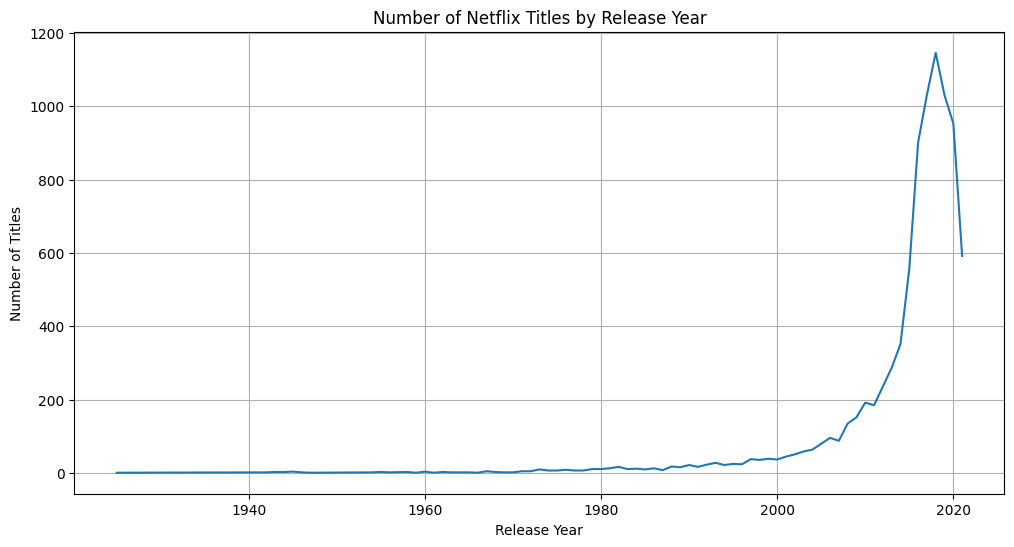

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(year_counts.index, year_counts.values)

plt.title('Number of Netflix Titles by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.grid(True)
plt.show()

### Observation

The number of Netflix titles varies across release years. The dataset contains a relatively larger number of titles from recent years, indicating that Netflix's content library is concentrated more heavily in newer releases.

## Question 3: Which countries have the highest number of Netflix titles?

We analyze the `country` column to identify the countries associated with the highest number of Netflix titles.

In [15]:
country_counts = (
    df['country']
    .str.split(', ')
    .explode()
    .str.strip()
    .value_counts()
)

print(country_counts.head(10))

country
United States     3680
India             1046
Unknown            830
United Kingdom     803
Canada             445
France             393
Japan              317
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64


In [16]:
country_counts = country_counts.drop('Unknown', errors='ignore')

print(country_counts.head(10))

country
United States     3680
India             1046
United Kingdom     803
Canada             445
France             393
Japan              317
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


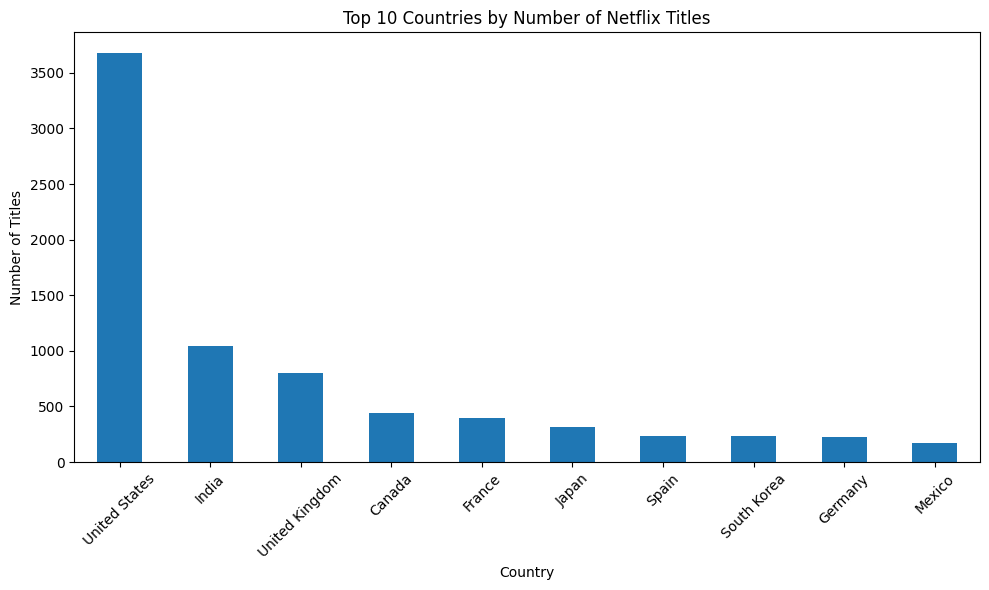

In [17]:
plt.figure(figsize=(10, 6))

country_counts.head(10).plot(kind='bar')

plt.title('Top 10 Countries by Number of Netflix Titles')
plt.xlabel('Country')
plt.ylabel('Number of Titles')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation

The United States is associated with the highest number of Netflix titles in the dataset, followed by India and the United Kingdom. The distribution shows that Netflix's content is associated with productions from a wide range of countries.

## Question 4: What are the most common content ratings on Netflix?

We analyze the `rating` column to identify the most frequently occurring content ratings in the Netflix dataset.

In [18]:
rating_counts = df['rating'].value_counts()

print(rating_counts)


rating
TV-MA       3209
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


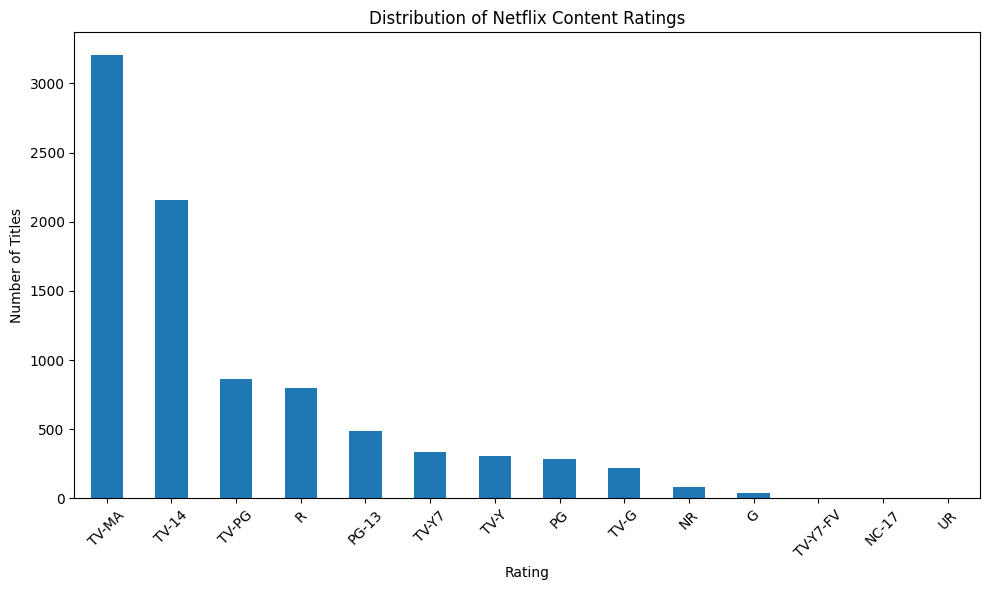

In [19]:
plt.figure(figsize=(10, 6))

rating_counts.plot(kind='bar')

plt.title('Distribution of Netflix Content Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation

The distribution shows that Netflix content is spread across several audience ratings. The most frequently occurring ratings represent the largest categories of content in the dataset, while some ratings have considerably fewer titles.

## Question 5: Which genres/categories are most common on Netflix?

We analyze the `listed_in` column to identify the most frequently occurring genres and categories in the Netflix dataset.

In [20]:
genre_counts = (
    df['listed_in']
    .str.split(', ')
    .explode()
    .str.strip()
    .value_counts()
)

print(genre_counts.head(10))

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1350
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


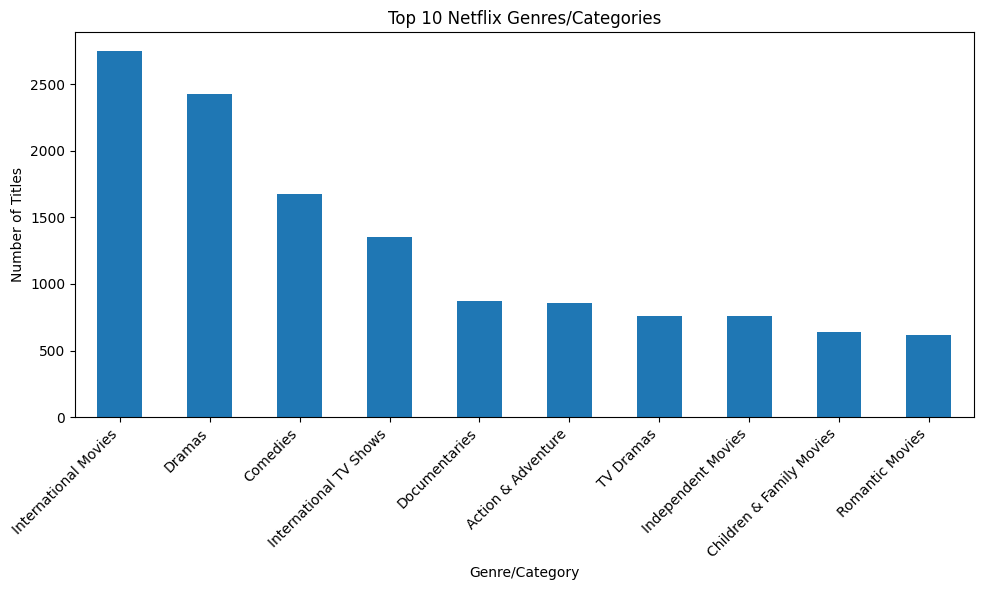

In [21]:
plt.figure(figsize=(10, 6))

genre_counts.head(10).plot(kind='bar')

plt.title('Top 10 Netflix Genres/Categories')
plt.xlabel('Genre/Category')
plt.ylabel('Number of Titles')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Observation

The Netflix dataset contains a wide variety of genres and categories. The top categories have a considerably larger number of titles than some of the less frequently occurring categories, showing that Netflix's content library is concentrated in certain popular genres.

## Question 6: What is the distribution of movie durations?

We analyze the duration of movies in minutes to understand how movie lengths are distributed in the Netflix dataset.

In [22]:
movies = df[df['type'] == 'Movie'].copy()

print("Number of movies:", len(movies))

Number of movies: 6128


In [23]:
movies['duration_minutes'] = (
    movies['duration']
    .str.replace(' min', '', regex=False)
    .astype(int)
)

print(movies['duration_minutes'].head())

0      90
6      91
7     125
9     104
12    127
Name: duration_minutes, dtype: int64


In [24]:
print(movies['duration_minutes'].describe())

count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_minutes, dtype: float64


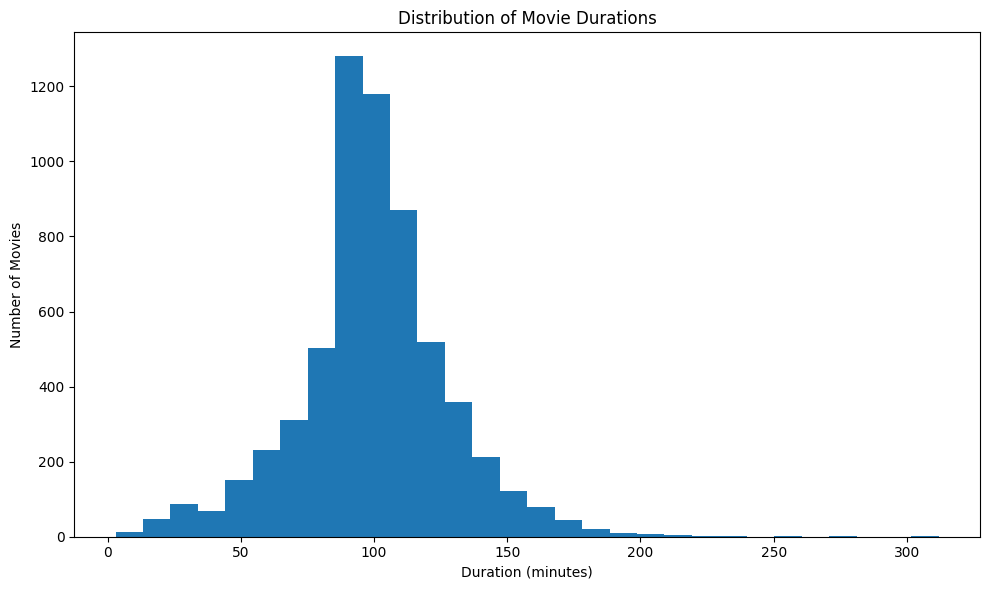

In [25]:
plt.figure(figsize=(10, 6))

plt.hist(movies['duration_minutes'], bins=30)

plt.title('Distribution of Movie Durations')
plt.xlabel('Duration (minutes)')
plt.ylabel('Number of Movies')

plt.tight_layout()
plt.show()

### Observation

The movie durations show a range of values, with most movies concentrated within a particular duration range. The histogram helps identify the typical length of movies and shows how frequently shorter and longer movies occur in the dataset.

## Question 7: Which years had the highest number of titles added to Netflix?

We analyze the `year_added` column to identify the years in which the largest number of titles were added to Netflix.

In [26]:
added_year_counts = df['year_added'].value_counts().sort_index()

print(added_year_counts)

year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     427
2017.0    1187
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: count, dtype: int64


In [27]:
top_added_years = df['year_added'].value_counts().head(10)

print(top_added_years)

year_added
2019.0    2016
2020.0    1879
2018.0    1649
2021.0    1498
2017.0    1187
2016.0     427
2015.0      82
2014.0      24
2011.0      13
2013.0      11
Name: count, dtype: int64


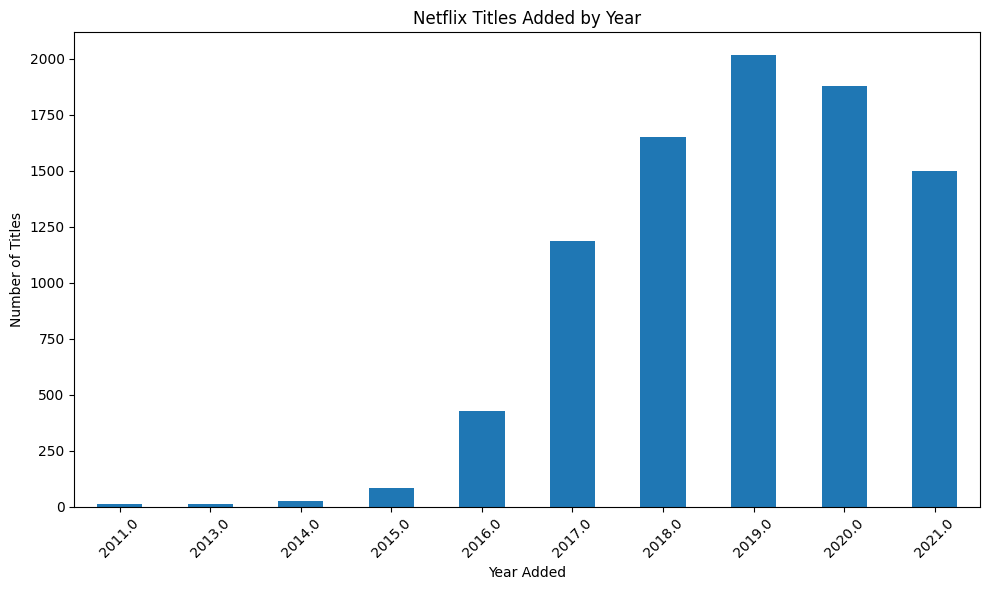

In [28]:
plt.figure(figsize=(10, 6))

top_added_years.sort_index().plot(kind='bar')

plt.title('Netflix Titles Added by Year')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation

The number of titles added to Netflix varies across the years. Some years show substantially higher additions than others, indicating periods when Netflix added a larger volume of content to its catalog.

## Question 8: Which months had the highest number of Netflix titles added?

We analyze the `month_added` column to determine which months had the highest number of Netflix titles added to the platform.

In [29]:
month_counts = df['month_added'].value_counts()

print(month_counts)

month_added
July         827
December     813
September    769
April        763
October      760
August       754
March        742
January      738
June         728
November     705
May          632
February     563
Name: count, dtype: int64


In [30]:
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

month_counts = month_counts.reindex(month_order)

print(month_counts)

month_added
January      738
February     563
March        742
April        763
May          632
June         728
July         827
August       754
September    769
October      760
November     705
December     813
Name: count, dtype: int64


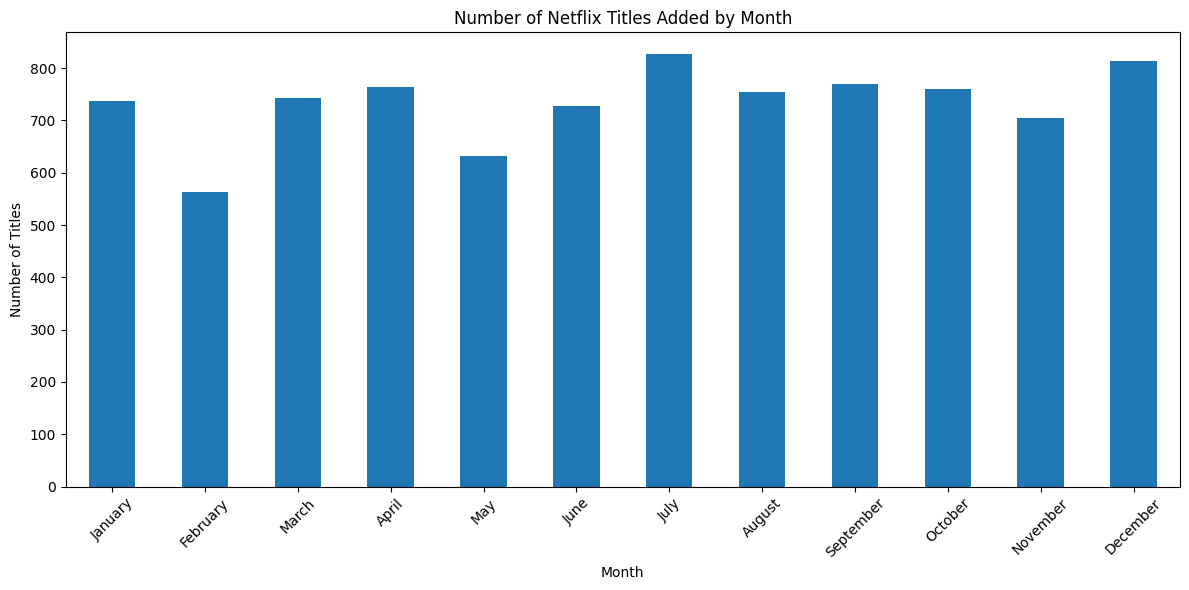

In [31]:
plt.figure(figsize=(12, 6))

month_counts.plot(kind='bar')

plt.title('Number of Netflix Titles Added by Month')
plt.xlabel('Month')
plt.ylabel('Number of Titles')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
highest_month = month_counts.idxmax()
highest_month_count = month_counts.max()

print("Month with the highest number of additions:", highest_month)
print("Number of titles added:", highest_month_count)

Month with the highest number of additions: July
Number of titles added: 827


### Observation

The number of Netflix titles added varies across the months. The month with the highest number of additions represents the period in which the largest volume of content was added to the Netflix catalog, while other months show comparatively fewer additions.

## Question 9: How does the distribution of ratings differ between Movies and TV Shows?

We compare the content ratings of Movies and TV Shows to understand how the rating distribution varies between the two types of Netflix content.

In [33]:
rating_type = pd.crosstab(df['rating'], df['type'])

print(rating_type)

type      Movie  TV Show
rating                  
G            41        0
NC-17         3        0
NR           75        4
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      730
TV-G        126       94
TV-MA      2064     1145
TV-PG       540      321
TV-Y        131      175
TV-Y7       139      194
TV-Y7-FV      5        1
UR            3        0


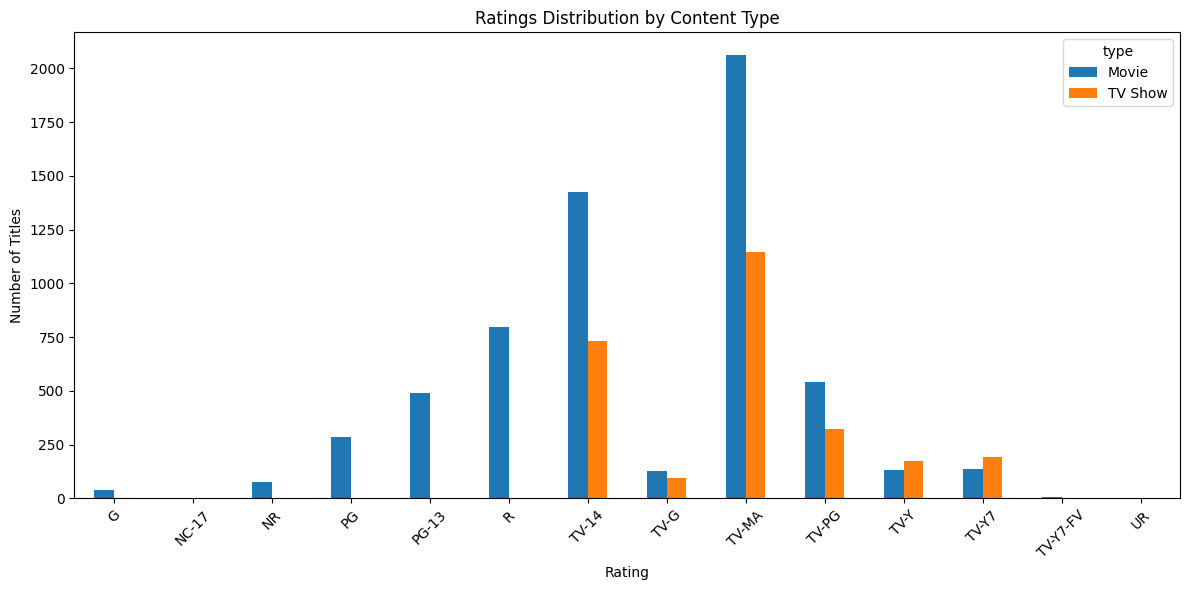

In [34]:
rating_type.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Ratings Distribution by Content Type')
plt.xlabel('Rating')
plt.ylabel('Number of Titles')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation

The rating distribution differs between Movies and TV Shows. Some ratings are more frequently associated with Movies, while others have a larger representation among TV Shows. The grouped bar chart allows the differences between the two content types to be compared across ratings.

## Question 10: Which countries have the most Movies and TV Shows?

We analyze the relationship between country and content type to compare the number of Movies and TV Shows associated with different countries.

In [35]:
country_type_df = df[['country', 'type']].copy()

country_type_df['country'] = country_type_df['country'].str.split(', ')

country_type_df = country_type_df.explode('country')

country_type_df['country'] = country_type_df['country'].str.strip()

print(country_type_df.head())

         country     type
0  United States    Movie
1   South Africa  TV Show
2        Unknown  TV Show
3        Unknown  TV Show
4          India  TV Show


In [36]:
country_type_df = country_type_df[
    country_type_df['country'] != 'Unknown'
]

print(country_type_df.head())

         country     type
0  United States    Movie
1   South Africa  TV Show
4          India  TV Show
7  United States    Movie
7          Ghana    Movie


In [37]:
country_type_counts = (
    country_type_df
    .groupby(['country', 'type'])
    .size()
    .reset_index(name='count')
)

top_countries = (
    country_type_counts
    .groupby('country')['count']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_countries)

country
United States     3680
India             1046
United Kingdom     803
Canada             445
France             393
Japan              317
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


In [38]:
top_country_names = top_countries.index

plot_data = country_type_counts[
    country_type_counts['country'].isin(top_country_names)
]

plot_data = plot_data.pivot(
    index='country',
    columns='type',
    values='count'
).fillna(0)

print(plot_data)

type            Movie  TV Show
country                       
Canada            319      126
France            303       90
Germany           182       44
India             962       84
Japan             119      198
Mexico            111       58
South Korea        61      170
Spain             171       61
United Kingdom    532      271
United States    2748      932


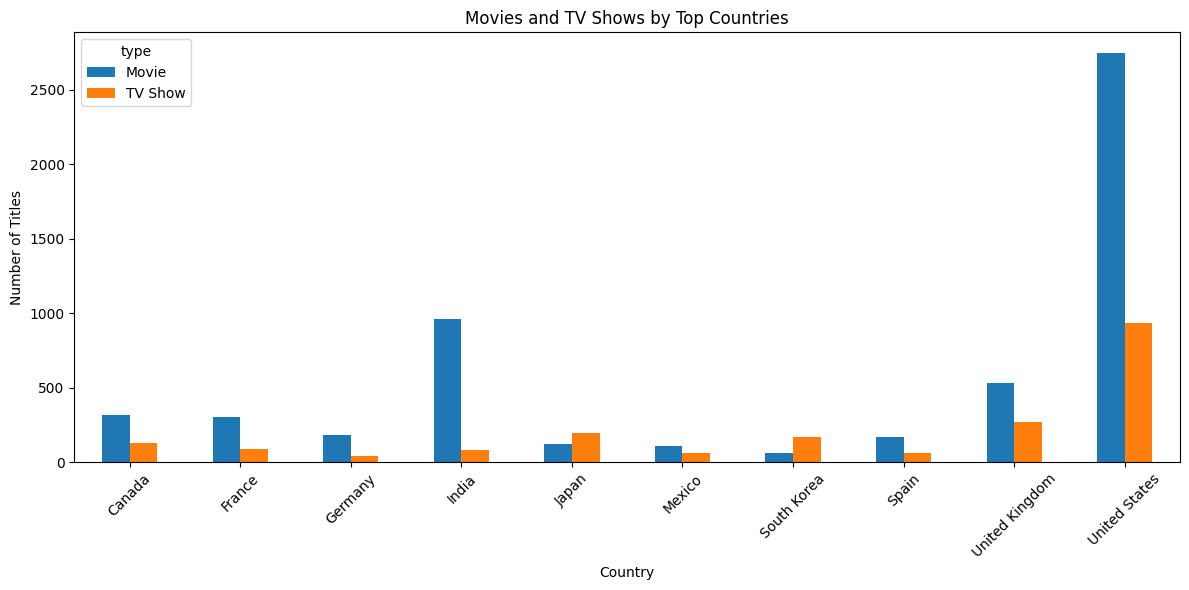

In [39]:
plot_data.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Movies and TV Shows by Top Countries')
plt.xlabel('Country')
plt.ylabel('Number of Titles')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation

The distribution of Movies and TV Shows varies across countries. Some countries have a substantially larger number of Movies than TV Shows, while the difference is smaller for other countries. This indicates that the type of Netflix content associated with each country varies across the dataset.

## Question 11: How has the addition of Movies and TV Shows changed over time?

We analyze the relationship between the year a title was added to Netflix and its content type to understand how the addition of Movies and TV Shows has changed over time.

In [40]:
year_type_counts = pd.crosstab(
    df['year_added'],
    df['type']
)

print(year_type_counts)

type        Movie  TV Show
year_added                
2008.0          1        1
2009.0          2        0
2010.0          1        0
2011.0         13        0
2012.0          3        0
2013.0          6        5
2014.0         19        5
2015.0         56       26
2016.0        251      176
2017.0        838      349
2018.0       1237      412
2019.0       1424      592
2020.0       1284      595
2021.0        993      505


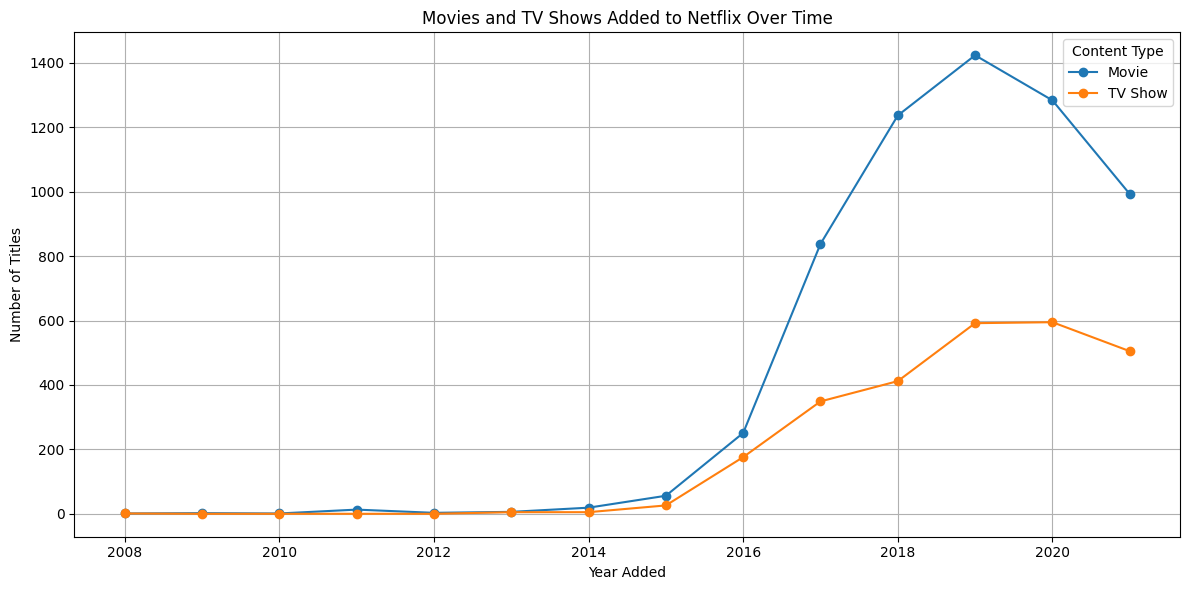

In [41]:
year_type_counts.plot(
    kind='line',
    figsize=(12, 6),
    marker='o'
)

plt.title('Movies and TV Shows Added to Netflix Over Time')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')

plt.legend(title='Content Type')
plt.grid(True)

plt.tight_layout()
plt.show()

In [42]:
print("Movie peak year:")
print(year_type_counts['Movie'].idxmax())
print("Number of Movies:", year_type_counts['Movie'].max())

print("\nTV Show peak year:")
print(year_type_counts['TV Show'].idxmax())
print("Number of TV Shows:", year_type_counts['TV Show'].max())

Movie peak year:
2019.0
Number of Movies: 1424

TV Show peak year:
2020.0
Number of TV Shows: 595


### Observation

The number of Movies and TV Shows added to Netflix varies across the years. The two content types show different patterns over time, with some years having substantially more additions than others. The line chart helps compare how the addition of Movies and TV Shows changed across the observed period.

## Question 12: What is the relationship between release year and year added to Netflix?

We compare the original release year of a title with the year it was added to Netflix to understand the relationship between content release and its addition to the Netflix catalog.

In [43]:
release_added = df[['release_year', 'year_added']].dropna()

print(release_added.head())

   release_year  year_added
0          2020      2021.0
1          2021      2021.0
2          2021      2021.0
3          2021      2021.0
4          2021      2021.0


In [44]:
release_added['years_to_add'] = (
    release_added['year_added'] - release_added['release_year']
)

print(release_added['years_to_add'].describe())

count    8794.000000
mean        4.689220
std         8.788256
min        -3.000000
25%         0.000000
50%         1.000000
75%         5.000000
max        93.000000
Name: years_to_add, dtype: float64


In [45]:
average_gap = release_added['years_to_add'].mean()

print("Average number of years between release and Netflix addition:",
      round(average_gap, 2))

Average number of years between release and Netflix addition: 4.69


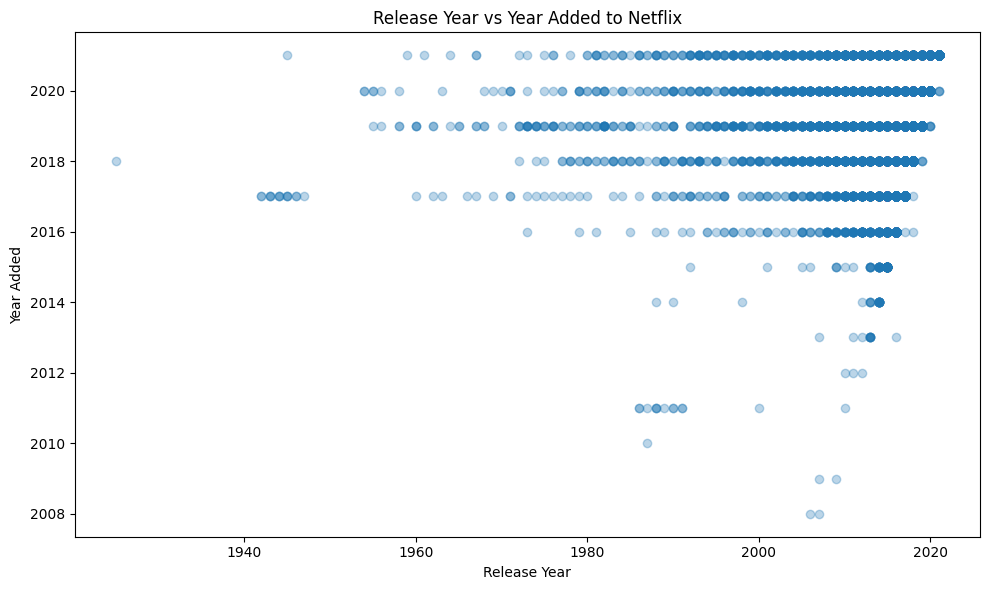

In [46]:
plt.figure(figsize=(10, 6))

plt.scatter(
    release_added['release_year'],
    release_added['year_added'],
    alpha=0.3
)

plt.title('Release Year vs Year Added to Netflix')
plt.xlabel('Release Year')
plt.ylabel('Year Added')

plt.tight_layout()
plt.show()

### Observation

The scatter plot shows the relationship between the original release year and the year titles were added to Netflix. Many titles were added relatively close to their original release year, while some titles have a larger gap between release and Netflix addition. This indicates that Netflix's catalog contains both relatively recent releases and older content.

## Question 13: Which directors have the most titles on Netflix?

We analyze the `director` column to identify the directors associated with the highest number of titles in the Netflix dataset.

In [47]:
director_counts = df['director'].value_counts()

print(director_counts.head(10))

director
Unknown                   2624
Rajiv Chilaka               19
Raúl Campos, Jan Suter      18
Marcus Raboy                16
Suhas Kadav                 16
Jay Karas                   14
Cathy Garcia-Molina         13
Jay Chapman                 12
Youssef Chahine             12
Martin Scorsese             12
Name: count, dtype: int64


In [48]:
director_counts = director_counts.drop('Unknown', errors='ignore')

print(director_counts.head(10))

director
Rajiv Chilaka             19
Raúl Campos, Jan Suter    18
Marcus Raboy              16
Suhas Kadav               16
Jay Karas                 14
Cathy Garcia-Molina       13
Jay Chapman               12
Youssef Chahine           12
Martin Scorsese           12
Steven Spielberg          11
Name: count, dtype: int64


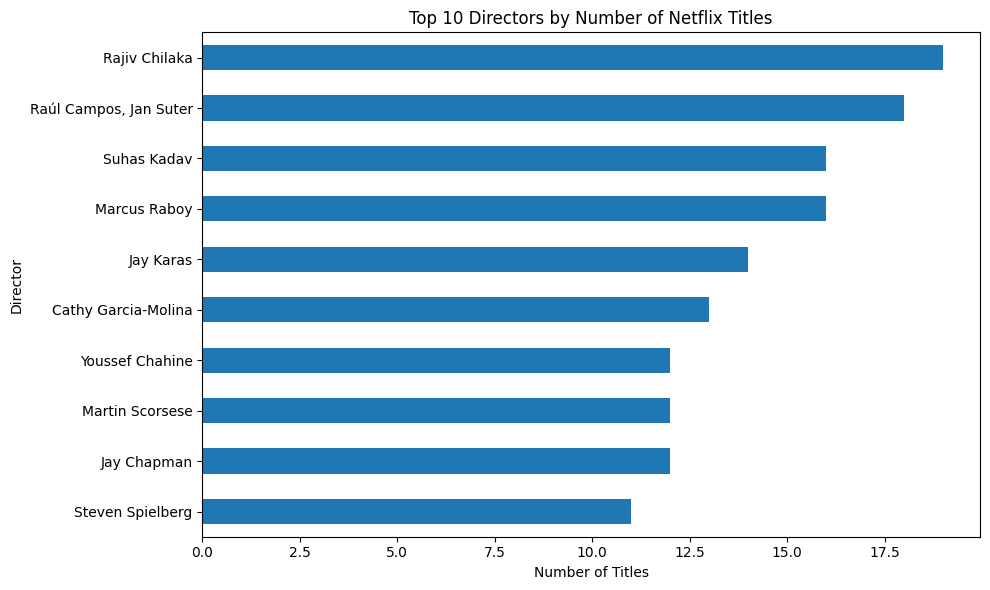

In [49]:
plt.figure(figsize=(10, 6))

director_counts.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Directors by Number of Netflix Titles')
plt.xlabel('Number of Titles')
plt.ylabel('Director')

plt.tight_layout()
plt.show()

### Observation

The analysis shows that a relatively small number of directors are associated with multiple titles in the Netflix dataset. The top directors have considerably more titles than many other directors, while a large number of directors are associated with only one or a small number of titles.

## Question 14: What are the most common movie durations?

We analyze movie durations to identify the durations that occur most frequently in the Netflix dataset.

In [50]:
movies = df[df['type'] == 'Movie'].copy()


In [51]:
movies['duration_minutes'] = (
    movies['duration']
    .str.replace(' min', '', regex=False)
    .astype(int)
)

print(movies['duration_minutes'].head())

0      90
6      91
7     125
9     104
12    127
Name: duration_minutes, dtype: int64


In [52]:
duration_counts = movies['duration_minutes'].value_counts()

print(duration_counts.head(10))

duration_minutes
90     152
97     146
94     146
93     146
91     144
95     137
96     130
92     129
102    122
98     120
Name: count, dtype: int64


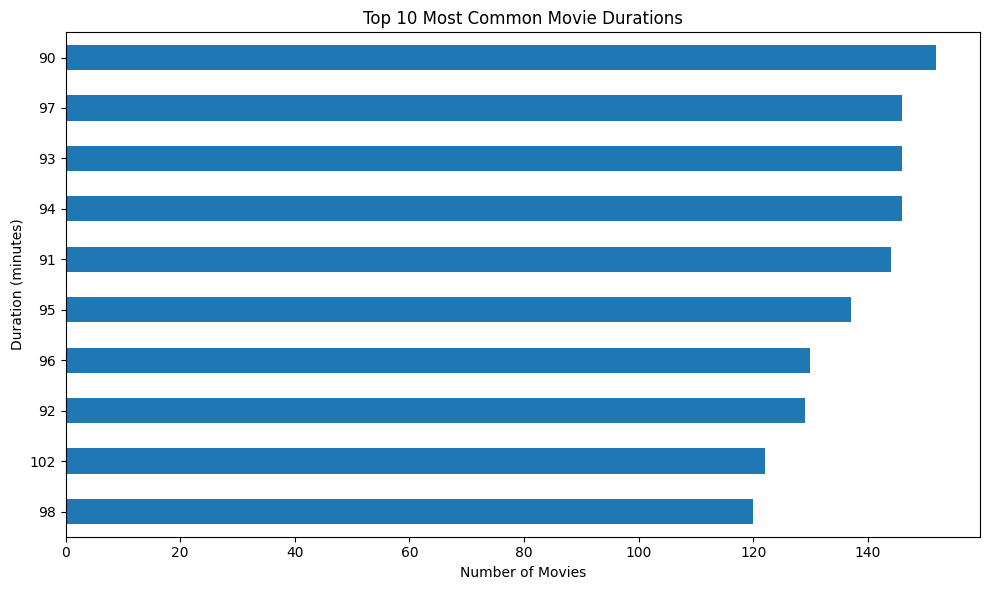

In [53]:
plt.figure(figsize=(10, 6))

duration_counts.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Most Common Movie Durations')
plt.xlabel('Number of Movies')
plt.ylabel('Duration (minutes)')

plt.tight_layout()
plt.show()

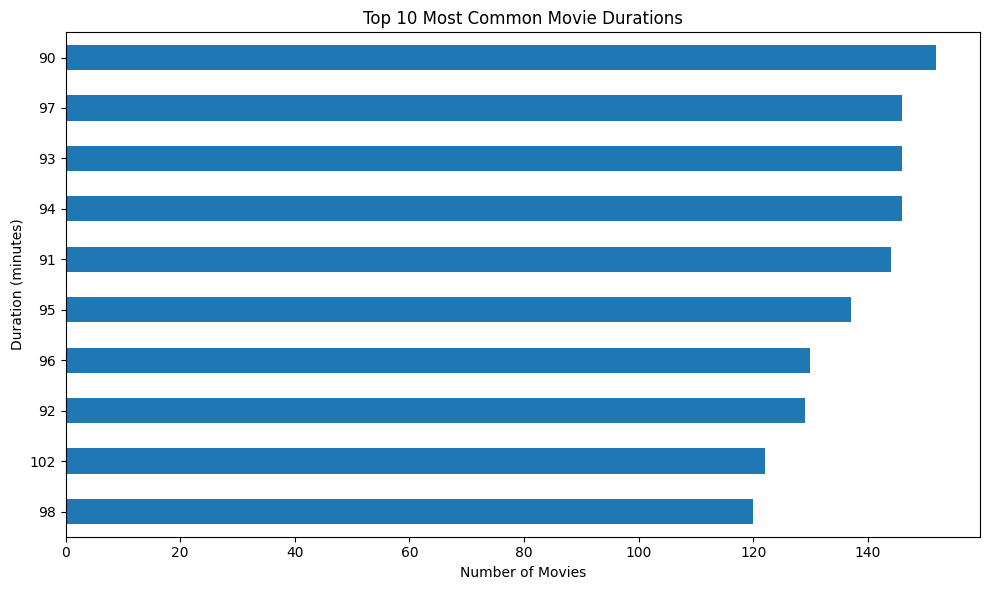

In [54]:
plt.figure(figsize=(10, 6))

duration_counts.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Most Common Movie Durations')
plt.xlabel('Number of Movies')
plt.ylabel('Duration (minutes)')

plt.tight_layout()
plt.show()

In [55]:
most_common_duration = duration_counts.idxmax()
most_common_duration_count = duration_counts.max()

print("Most common movie duration:", most_common_duration, "minutes")
print("Number of movies:", most_common_duration_count)

Most common movie duration: 90 minutes
Number of movies: 152


### Observation

The analysis identifies the movie durations that occur most frequently in the Netflix dataset. The most common duration represents a frequently occurring running time in the movie catalog, while other durations occur less frequently.

## Question 15: How does Netflix content vary across different ratings?

We analyze the distribution of Movies and TV Shows within different content ratings using percentages to understand how the content types vary across ratings.

In [56]:
rating_type_percent = pd.crosstab(
    df['rating'],
    df['type'],
    normalize='index'
) * 100

print(rating_type_percent.round(2))

type       Movie  TV Show
rating                   
G         100.00     0.00
NC-17     100.00     0.00
NR         94.94     5.06
PG        100.00     0.00
PG-13     100.00     0.00
R          99.75     0.25
TV-14      66.16    33.84
TV-G       57.27    42.73
TV-MA      64.32    35.68
TV-PG      62.72    37.28
TV-Y       42.81    57.19
TV-Y7      41.74    58.26
TV-Y7-FV   83.33    16.67
UR        100.00     0.00


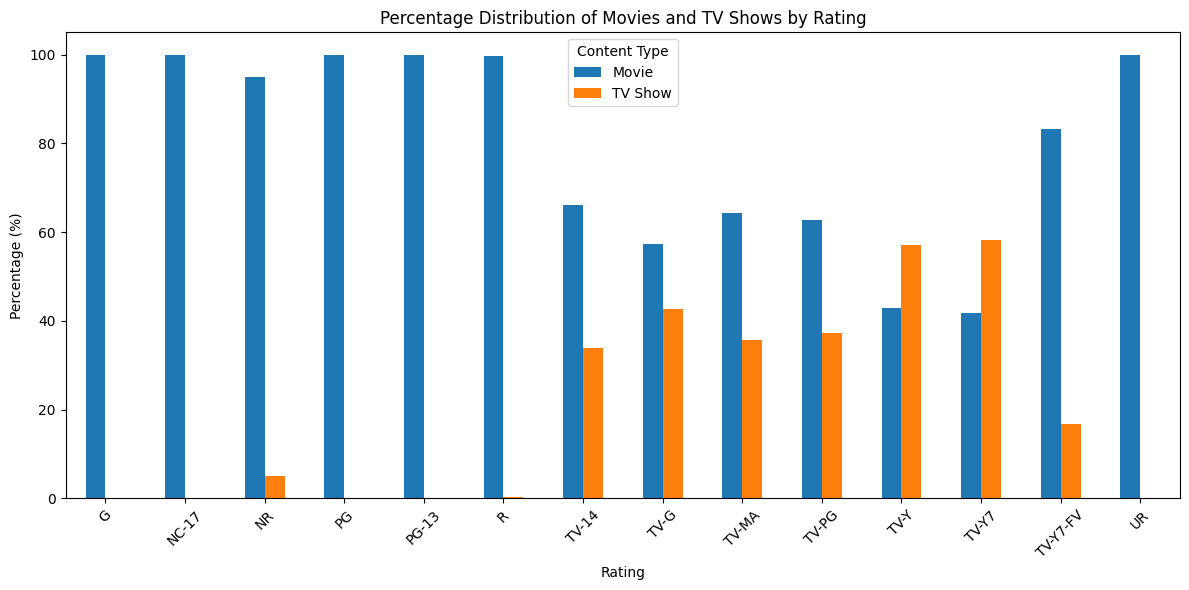

In [57]:
rating_type_percent.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Percentage Distribution of Movies and TV Shows by Rating')
plt.xlabel('Rating')
plt.ylabel('Percentage (%)')

plt.xticks(rotation=45)
plt.legend(title='Content Type')

plt.tight_layout()
plt.show()

### Observation

The percentage distribution shows that the proportion of Movies and TV Shows varies across content ratings. Some ratings have a greater representation of Movies, while other ratings have a relatively larger representation of TV Shows. This demonstrates differences in the rating composition of the two content types.

# Final Conclusion

The Exploratory Data Analysis of the Netflix dataset helped us understand the characteristics and patterns of Netflix's content library.

The analysis showed that Movies form a larger portion of the dataset than TV Shows. We also examined the distribution of content across release years, countries, ratings, genres, movie durations, and the years and months in which titles were added to Netflix.

The analysis of countries showed that Netflix titles are associated with productions from many different countries. Genre analysis revealed that certain categories occur more frequently than others.

We also compared Movies and TV Shows across ratings and countries, examined how content additions changed over time, and studied the relationship between a title's original release year and the year it was added to Netflix.

Overall, EDA helped us identify important patterns, distributions, and relationships in the Netflix dataset through statistical analysis and data visualization.

# Key Findings

1. Movies make up the larger share of the Netflix dataset compared with TV Shows.

2. Netflix titles are distributed across a wide range of release years, with more content concentrated in recent release years.

3. The Netflix catalog contains titles associated with many countries, with some countries contributing substantially more titles than others.

4. Netflix content is distributed across several different audience ratings.

5. The dataset contains a wide variety of genres and categories.

6. Movie durations vary considerably, with certain running times occurring more frequently.

7. The number of titles added to Netflix varies across different years and months.

8. The distribution of ratings differs between Movies and TV Shows.

9. The number and type of Netflix titles associated with countries varies across the dataset.

10. The relationship between release year and year added shows that Netflix contains both relatively recent releases and older content.

# Netflix Content — Exploratory Data Analysis

## FDS Project

### Objective

To explore and analyze the Netflix dataset using Python, Pandas, Matplotlib, and Seaborn to identify patterns, trends, distributions, and relationships in Netflix content.

## Dataset Overview

The cleaned Netflix dataset contains information about Movies and TV Shows, including their type, title, country, release year, rating, duration, genres, and date added.

## Tools and Libraries Used

- Python
- Pandas — data manipulation and analysis
- Matplotlib — data visualization
- Seaborn — statistical visualization
- Jupyter Notebook — development environment

## EDA Methodology

The following steps were followed during the analysis:

1. Loaded the cleaned Netflix dataset.
2. Inspected the dataset structure and dimensions.
3. Checked column names and data types.
4. Verified missing values.
5. Analyzed categorical and numerical variables.
6. Grouped and aggregated data to identify patterns.
7. Created visualizations using Matplotlib and Seaborn.
8. Compared different categories such as Movies and TV Shows.
9. Analyzed trends across years and months.
10. Interpreted the results and documented observations.

### Observation

July had the highest number of Netflix title additions, with 827 titles added. The number of additions varies across the months, showing that content was not added uniformly throughout the year.